# 02 — Thresholding baseline (rule-based amplitude / gradient / variance)

A rule-based **binary** artifact detector (`artifact` vs `rest`) evaluated with
Leave-One-Subject-Out cross-validation. This is the simplest possible
classifier: three independent threshold rules, fitted on the training fold
only, where a window is flagged as an artifact if **any** rule fires.

It serves as the *baseline that every subsequent ML method must beat*. No
fine-grained labels and no label hierarchy are used here — only `artifact` vs
`rest`.

## Section 1 — Imports & configuration

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats  # noqa: F401  (kept available for ad-hoc inspection)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

CONFIG = {
    "DATA_DIR": Path("processed_xdf"),
    "OUTPUT_DIR": Path("processed_xdf/02_Thresholding_plots"),
    "SFREQ": 250,
    "GRAD_CANDIDATES": [2, 3, 5, 7, 10],
    "VAR_CANDIDATES":  [3, 5, 7, 10, 15],
}

sns.set_theme(style="whitegrid")
print("CONFIG:")
for k, v in CONFIG.items():
    print(f"  {k:16s}: {v}")

CONFIG:
  DATA_DIR        : processed_xdf
  OUTPUT_DIR      : processed_xdf\02_Thresholding_plots
  SFREQ           : 250
  GRAD_CANDIDATES : [2, 3, 5, 7, 10]
  VAR_CANDIDATES  : [3, 5, 7, 10, 15]


## Section 2 — Load data

Load the two pickle bundles produced by `01_Preprocessing`:

* `features.pkl` — engineered features `X` plus all label levels and
  `subject_ids` (used here only for its labels / subjects).
* `windows_raw.pkl` — the raw window arrays `windows_raw`
  (`n_windows × n_channels × n_samples`) that the threshold rules operate on.

We verify the two bundles are row-aligned (same `subject_ids` and `y_fine`
ordering) before using `y_level1` from `features.pkl` as the ground truth for
the raw windows.

In [2]:
features_path = CONFIG["DATA_DIR"] / "features.pkl"
windows_path  = CONFIG["DATA_DIR"] / "windows_raw.pkl"

with features_path.open("rb") as f:
    features = pickle.load(f)
with windows_path.open("rb") as f:
    windows_bundle = pickle.load(f)

y_level1      = np.asarray(features["y_level1"])
y_fine        = np.asarray(features["y_fine"])
subject_ids   = np.asarray(features["subject_ids"])

windows_raw   = np.asarray(windows_bundle["windows_raw"])
windows_subj  = np.asarray(windows_bundle["subject_ids"])
windows_fine  = np.asarray(windows_bundle["y_fine"])

n_windows, n_channels, n_samples = windows_raw.shape
print(f"windows_raw shape : {windows_raw.shape} "
      f"({n_windows} windows, {n_channels} channels, {n_samples} samples)")

# --- Alignment checks: the raw windows must line up with the feature labels. ---
assert windows_raw.shape[0] == y_level1.shape[0], (
    f"row mismatch: windows_raw has {windows_raw.shape[0]} rows but "
    f"y_level1 has {y_level1.shape[0]}")
assert np.array_equal(windows_subj.astype(str), subject_ids.astype(str)), \
    "subject_ids differ between windows_raw.pkl and features.pkl"
assert np.array_equal(windows_fine.astype(str), y_fine.astype(str)), \
    "y_fine differs between windows_raw.pkl and features.pkl"
print("Alignment OK: windows_raw rows match y_level1 / subject_ids / y_fine.")

# --- Level-1 class distribution (the only labels used in this notebook). ---
dist = pd.Series(y_level1).value_counts()
dist_pct = (dist / dist.sum() * 100).round(1)
print("\nLevel-1 class distribution (artifact vs rest):")
print(pd.DataFrame({"count": dist, "pct": dist_pct}).to_string())

subjects = sorted(np.unique(subject_ids).tolist())
print(f"\nSubjects ({len(subjects)}): {subjects}")

windows_raw shape : (11418, 4, 500) (11418 windows, 4 channels, 500 samples)
Alignment OK: windows_raw rows match y_level1 / subject_ids / y_fine.

Level-1 class distribution (artifact vs rest):
          count   pct
artifact   5907  51.7
rest       5511  48.3

Subjects (13): ['sub-0b11bec3', 'sub-123051bf', 'sub-160f8068', 'sub-2cbce981', 'sub-3f0ec71e', 'sub-413e6462', 'sub-81091e67', 'sub-9c5349dc', 'sub-b835837a', 'sub-bf3d1a74', 'sub-d0bb067d', 'sub-ece8d790', 'sub-f415eee8']


## Section 3 — Per-subject z-score normalisation

Before any threshold is computed, each window is z-scored **per channel** using
statistics estimated from that fold's *training rest* windows only. This
removes inter-subject amplitude variability so a threshold value can be read as
"*N standard deviations above the resting baseline*" rather than an absolute µV
level — which matters because subjects have very different raw EEG amplitudes.

To avoid leakage the statistics are fitted **only** on the training fold's rest
windows (`y_level1[train_idx] == "rest"`) and then applied to *all* windows
(train and test) of that fold. The per-channel `mean` / `std` therefore have
shape `(n_channels, 1)` so they broadcast across the time-sample axis of a
`(n_windows, n_channels, n_samples)` array. The normalisation is performed
inside the LOSO loop in Section 4; the helpers are defined here.

### Why normalise here, but not for the Random-Forest features?

The RF model consumes engineered features and splits the data with decision
trees. Tree splits depend only on the *ordering* of values, so they are
invariant to any monotonic per-feature transformation — scaling or centring a
feature cannot change which threshold a split chooses. Per-subject
normalisation would not change RF behaviour, so it was skipped there.

Threshold rules are different: they compare raw signal statistics against
**fixed numeric constants** (`amp_thresh`, `G`, `k_var · var_base`). Those
comparisons are *not* scale-invariant — a constant calibrated for a
low-amplitude subject would misfire on a high-amplitude subject. Normalising
each subject to a common baseline is what makes a single set of thresholds
transferable across subjects.

In [3]:
def compute_norm_stats(rest_windows: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Per-channel mean and std estimated from training rest windows.

    Parameters
    ----------
    rest_windows : np.ndarray, shape (n_rest, n_channels, n_samples)
        The training fold's resting windows.

    Returns
    -------
    mean, std : np.ndarray, each shape (n_channels, 1)
        Per-channel statistics, shaped for broadcasting across the sample axis.
        A zero std is replaced by 1.0 to avoid division by zero.
    """
    mean = rest_windows.mean(axis=(0, 2)).reshape(-1, 1)
    std  = rest_windows.std(axis=(0, 2)).reshape(-1, 1)
    std = np.where(std == 0.0, 1.0, std)
    return mean, std


def normalize_windows(
    windows: np.ndarray, mean: np.ndarray, std: np.ndarray
) -> np.ndarray:
    """Apply per-channel z-scoring to every window.

    Parameters
    ----------
    windows : np.ndarray, shape (n_windows, n_channels, n_samples)
    mean, std : np.ndarray, each shape (n_channels, 1)
        Statistics from :func:`compute_norm_stats` (fitted on training rest).

    Returns
    -------
    np.ndarray, shape (n_windows, n_channels, n_samples)
        The z-scored windows. ``(n_channels, 1)`` stats broadcast across both
        the window axis and the sample axis.
    """
    return (windows - mean) / std

## Section 4 — LOSO cross-validation with grid search

One subject is held out per fold. For each fold:

1. Split `windows_raw` / `y_level1` into train and test by `subject_id`.
2. Fit per-channel normalisation stats on the **training rest** windows and
   apply them to all windows of the fold.
3. Pre-compute three per-window statistics **once** (before the grid search):
   * `max_abs`  — max absolute value over all channels and samples,
   * `max_grad` — max absolute first difference over all channels,
   * `max_var`  — max per-channel variance over channels.
4. Grid-search the three thresholds on the **training windows only**, choosing
   the combination with the best macro-F1, and apply it unchanged to the test
   fold.

**Threshold rules** (a window is `artifact` if *any* rule fires):

```
amp_fire   = max_abs  > params["amp_thresh"]
grad_fire  = max_grad > params["G"]
var_fire   = max_var  > params["k_var"] * params["var_base"]
prediction = "artifact" if (amp_fire or grad_fire or var_fire) else "rest"
```

**Candidate grids** (all derived from the training fold):

* amplitude — union of `percentile(max_abs_rest, [90, 95, 99])` and
  `percentile(max_abs_artifact, [10, 25, 50])`, deduplicated and sorted;
* gradient — `GRAD_CANDIDATES × median(max_grad_rest)`;
* variance — `VAR_CANDIDATES × mean(max_var_rest)`, where `var_base` is the
  mean of the per-window variance statistic over rest windows.

In [4]:
ARTIFACT, REST = "artifact", "rest"


def window_summaries(
    windows: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Per-window amplitude / gradient / variance statistics.

    Parameters
    ----------
    windows : np.ndarray, shape (n_windows, n_channels, n_samples)

    Returns
    -------
    max_abs  : np.ndarray, shape (n_windows,)
        Max absolute value across all channels and samples.
    max_grad : np.ndarray, shape (n_windows,)
        Max absolute first difference across all channels and samples.
    max_var  : np.ndarray, shape (n_windows,)
        Max per-channel variance across channels.
    """
    max_abs  = np.abs(windows).max(axis=(1, 2))
    max_grad = np.abs(np.diff(windows, axis=2)).max(axis=(1, 2))
    max_var  = windows.var(axis=2).max(axis=1)
    return max_abs, max_grad, max_var


def optimize_thresholds(
    max_abs: np.ndarray,
    max_grad: np.ndarray,
    max_var: np.ndarray,
    y: np.ndarray,
    config: dict,
) -> dict:
    """Grid-search the three thresholds on a training fold by macro-F1.

    All candidate grids are derived from the training windows only, so no
    information leaks from the held-out subject.

    Parameters
    ----------
    max_abs, max_grad, max_var : np.ndarray, shape (n_train,)
        Per-window statistics from :func:`window_summaries` for the train fold.
    y : np.ndarray of str, shape (n_train,)
        Level-1 labels (``"artifact"`` / ``"rest"``) for the train windows.
    config : dict
        Provides ``GRAD_CANDIDATES`` and ``VAR_CANDIDATES`` multiplier grids.

    Returns
    -------
    dict with keys ``amp_thresh``, ``G``, ``k_var``, ``var_base`` and
    ``best_f1_train`` describing the best-scoring combination.
    """
    rest_mask = (y == REST)
    art_mask  = (y == ARTIFACT)

    abs_rest, abs_art = max_abs[rest_mask], max_abs[art_mask]
    grad_base = float(np.median(max_grad[rest_mask]))   # signal / sample
    var_base  = float(np.mean(max_var[rest_mask]))      # mean rest variance

    amp_candidates = np.unique(np.concatenate([
        np.percentile(abs_rest, [90, 95, 99]),
        np.percentile(abs_art,  [10, 25, 50]),
    ]))

    best = {
        "amp_thresh": float(amp_candidates[-1]),
        "G": float("inf"),
        "k_var": float(config["VAR_CANDIDATES"][-1]),
        "var_base": var_base,
        "best_f1_train": -1.0,
    }

    for amp_th in amp_candidates:
        amp_fire = max_abs > amp_th
        for k_g in config["GRAD_CANDIDATES"]:
            G = k_g * grad_base
            grad_fire = max_grad > G
            for k_v in config["VAR_CANDIDATES"]:
                var_fire = max_var > (k_v * var_base)
                preds = np.where(amp_fire | grad_fire | var_fire,
                                 ARTIFACT, REST)
                f1 = f1_score(y, preds, average="macro",
                              labels=[ARTIFACT, REST], zero_division=0)
                if f1 > best["best_f1_train"]:
                    best = {
                        "amp_thresh":    float(amp_th),
                        "G":             float(G),
                        "k_var":         float(k_v),
                        "var_base":      var_base,
                        "best_f1_train": float(f1),
                    }
    return best


def apply_threshold_rules(
    max_abs: np.ndarray,
    max_grad: np.ndarray,
    max_var: np.ndarray,
    params: dict,
) -> np.ndarray:
    """Label each window ``"artifact"`` / ``"rest"`` from fitted thresholds.

    Parameters
    ----------
    max_abs, max_grad, max_var : np.ndarray, shape (n_windows,)
        Per-window statistics from :func:`window_summaries`.
    params : dict
        Output of :func:`optimize_thresholds`.

    Returns
    -------
    np.ndarray of str, shape (n_windows,)
        ``"artifact"`` where any rule fires, otherwise ``"rest"``.
    """
    amp_fire  = max_abs  > params["amp_thresh"]
    grad_fire = max_grad > params["G"]
    var_fire  = max_var  > (params["k_var"] * params["var_base"])
    return np.where(amp_fire | grad_fire | var_fire, ARTIFACT, REST)

In [5]:
y_true_all: list[str] = []
y_pred_all: list[str] = []
per_fold_metrics: list[dict] = []
param_log: list[dict] = []

for test_subject in subjects:
    test_mask = (subject_ids == test_subject)
    train_idx = np.where(~test_mask)[0]
    test_idx  = np.where(test_mask)[0]

    max_abs, max_grad, max_var = window_summaries(windows_raw)

    tr_abs,  tr_grad,  tr_var  = max_abs[train_idx], max_grad[train_idx], max_var[train_idx]
    te_abs,  te_grad,  te_var  = max_abs[test_idx],  max_grad[test_idx],  max_var[test_idx]
    y_train = y_level1[train_idx]
    y_test  = y_level1[test_idx]

    # --- Grid search on train, then apply unchanged to test. ---
    params = optimize_thresholds(tr_abs, tr_grad, tr_var, y_train, CONFIG)
    preds  = apply_threshold_rules(te_abs, te_grad, te_var, params)

    acc = accuracy_score(y_test, preds)
    f1m = f1_score(y_test, preds, average="macro", labels=[ARTIFACT, REST])

    per_fold_metrics.append({
        "subject": test_subject,
        "accuracy": acc,
        "f1_macro": f1m,
        "best_f1_train": params["best_f1_train"],
        "amp_thresh": params["amp_thresh"],
    })
    param_log.append({
        "subject":       test_subject,
        "amp_thresh":    params["amp_thresh"],
        "G":             params["G"],
        "k_var":         params["k_var"],
        "var_base":      params["var_base"],
        "best_f1_train": params["best_f1_train"],
        "n_test":        int(len(preds)),
    })

    y_true_all.extend(y_test.tolist())
    y_pred_all.extend(preds.tolist())

    print(f"{test_subject:14s}  acc={acc:.4f}  f1_macro={f1m:.4f}  "
          f"best_f1_train={params['best_f1_train']:.4f}  "
          f"amp_thresh={params['amp_thresh']:.3f}")

y_true = np.asarray(y_true_all)
y_pred = np.asarray(y_pred_all)

sub-0b11bec3    acc=0.7807  f1_macro=0.7681  best_f1_train=0.7720  amp_thresh=2.994
sub-123051bf    acc=0.9308  f1_macro=0.9306  best_f1_train=0.7589  amp_thresh=3.015
sub-160f8068    acc=0.7273  f1_macro=0.7139  best_f1_train=0.7767  amp_thresh=3.028
sub-2cbce981    acc=0.7633  f1_macro=0.7496  best_f1_train=0.7731  amp_thresh=2.993
sub-3f0ec71e    acc=0.5862  f1_macro=0.5611  best_f1_train=0.7899  amp_thresh=3.084
sub-413e6462    acc=0.7750  f1_macro=0.7603  best_f1_train=0.7719  amp_thresh=2.989
sub-81091e67    acc=0.8218  f1_macro=0.8172  best_f1_train=0.7689  amp_thresh=3.017
sub-9c5349dc    acc=0.8536  f1_macro=0.8536  best_f1_train=0.7654  amp_thresh=3.070
sub-b835837a    acc=0.7864  f1_macro=0.7810  best_f1_train=0.7713  amp_thresh=3.028
sub-bf3d1a74    acc=0.6159  f1_macro=0.6034  best_f1_train=0.7862  amp_thresh=3.091
sub-d0bb067d    acc=0.7503  f1_macro=0.7329  best_f1_train=0.7750  amp_thresh=3.003
sub-ece8d790    acc=0.8229  f1_macro=0.8217  best_f1_train=0.7670  amp_thres

## Section 5 — Results

Aggregate metrics over all LOSO folds, the full classification report, a
row-normalised confusion matrix, the per-fold macro-F1 (showing inter-subject
variability), and the per-fold fitted thresholds. All figures are written to
`CONFIG["OUTPUT_DIR"]`.

In [6]:
agg_acc = accuracy_score(y_true, y_pred)
agg_f1  = f1_score(y_true, y_pred, average="macro", labels=[ARTIFACT, REST])

print(f"Thresholding baseline — aggregate over {len(subjects)} LOSO folds")
print(f"  Accuracy : {agg_acc:.4f}")
print(f"  F1 macro : {agg_f1:.4f}")
print("\nClassification report (artifact vs rest):")
print(classification_report(y_true, y_pred,
                            labels=[REST, ARTIFACT],
                            target_names=[REST, ARTIFACT], digits=3))

Thresholding baseline — aggregate over 13 LOSO folds
  Accuracy : 0.7759
  F1 macro : 0.7706

Classification report (artifact vs rest):
              precision    recall  f1-score   support

        rest      0.854     0.646     0.736      5511
    artifact      0.731     0.897     0.805      5907

    accuracy                          0.776     11418
   macro avg      0.792     0.772     0.771     11418
weighted avg      0.790     0.776     0.772     11418



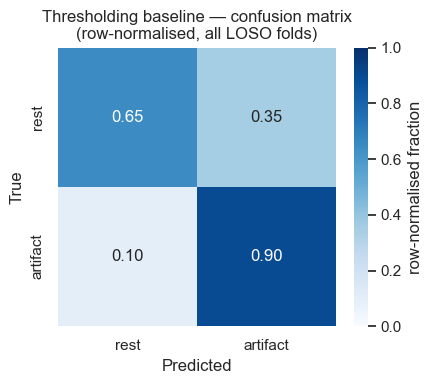

In [7]:
# Row-normalised confusion matrix (each true-class row sums to 1).
cm = confusion_matrix(y_true, y_pred, labels=[REST, ARTIFACT])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=[REST, ARTIFACT], yticklabels=[REST, ARTIFACT],
            cbar_kws={"label": "row-normalised fraction"}, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Thresholding baseline — confusion matrix\n(row-normalised, all LOSO folds)")
fig.tight_layout()
fig.savefig(CONFIG["OUTPUT_DIR"] / "thresholding_confusion_matrix.png", dpi=140)
plt.show()

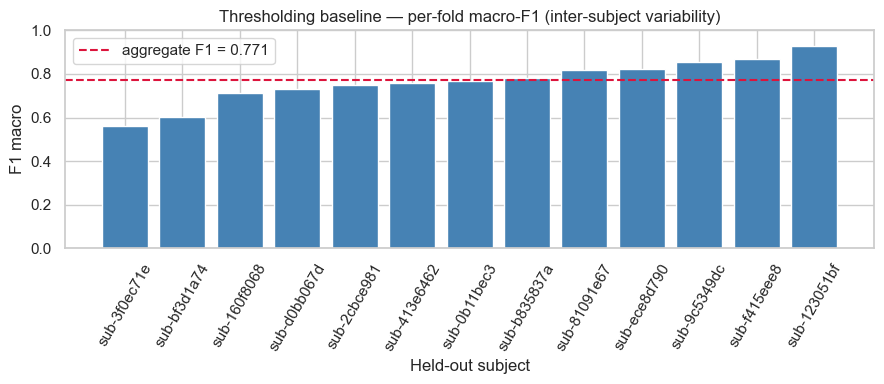

In [8]:
# Per-fold macro-F1 — visualises how much performance varies across subjects.
fold_df = pd.DataFrame(per_fold_metrics).sort_values("f1_macro")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(fold_df["subject"], fold_df["f1_macro"], color="steelblue")
ax.axhline(agg_f1, color="crimson", linestyle="--",
           label=f"aggregate F1 = {agg_f1:.3f}")
ax.set_ylabel("F1 macro")
ax.set_xlabel("Held-out subject")
ax.set_title("Thresholding baseline — per-fold macro-F1 (inter-subject variability)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=60)
ax.legend()
fig.tight_layout()
fig.savefig(CONFIG["OUTPUT_DIR"] / "thresholding_per_fold_f1.png", dpi=140)
plt.show()

In [9]:
# Per-fold fitted threshold parameters.
param_df = pd.DataFrame(param_log)[
    ["subject", "amp_thresh", "G", "k_var", "var_base", "best_f1_train", "n_test"]
]
print("Per-fold fitted threshold parameters:")
print(param_df.to_string(index=False))

Per-fold fitted threshold parameters:
     subject  amp_thresh        G  k_var   var_base  best_f1_train  n_test
sub-0b11bec3    2.994214 5.150003    3.0 121.136045       0.772002     880
sub-123051bf    3.015087 5.178663    3.0 121.923590       0.758888     881
sub-160f8068    3.028470 5.251776    3.0 121.897208       0.776671     880
sub-2cbce981    2.993238 4.725595    3.0 117.851547       0.773132     862
sub-3f0ec71e    3.083910 4.867473    3.0 120.779141       0.789856     870
sub-413e6462    2.989208 4.733130    3.0 121.737483       0.771925     880
sub-81091e67    3.016830 4.978504    3.0 120.902790       0.768890     881
sub-9c5349dc    3.070268 4.775384    3.0 120.644989       0.765414     881
sub-b835837a    3.028470 5.002125    3.0 121.740470       0.771274     880
sub-bf3d1a74    3.090970 5.049647    3.0 121.582433       0.786166     880
sub-d0bb067d    3.002776 4.808915    3.0  10.873485       0.774985     881
sub-ece8d790    3.042347 5.159195    3.0 121.282243       0.76

In [10]:
print("Thresholding baseline — LOSO aggregate")
print(f"  Accuracy : {agg_acc:.4f}")
print(f"  F1 macro : {agg_f1:.4f}")
print("  Note: binary artifact vs rest only")

Thresholding baseline — LOSO aggregate
  Accuracy : 0.7759
  F1 macro : 0.7706
  Note: binary artifact vs rest only
